## Sri's Metric

### Introduction

For my individual metric, I will investigate crime rates across Pittsburgh neighborhoods. I want to compare crime levels in different neighborhoods to determine which areas generally have lower crime and may offer a safer environment for residents.

### Metric

My individual metric is **reported crime levels** in each Pittsburgh neighborhood. I will compare the number of reported crimes across neighborhoods to identify areas with fewer reported incidents and potentially better socio-economic environments for residents.

### Dataset

I will use the [Monthly Criminal Activity](https://data.wprdc.org/dataset/monthly-criminal-activity-dashboard) from the Western Pennsylvania Regional Data Center (WPRDC).

This dataset contains reported crime incidents collected by the Pittsburgh Bureau of Police. It includes information such as the type of crime, date of occurrence, and neighborhood where the incident was reported. I will use these measurements to compare reported crime levels across different Pittsburgh neighborhoods.# Pittsburgh Crime Rate: Number of Committed Crimes by Neighborhood
## Sri’s metric

### Introduction
For my individual metric, I will investigate the number of reported crimes in different Pittsburgh neighborhoods. I want to compare crime levels across neighborhoods to determine which areas generally have the lowest and highest levels of criminal activity.

### Metric
My individual metric is the number of reported crimes in each Pittsburgh neighborhood. I will compare the total number of reported criminal incidents to determine which neighborhoods experience the most and fewest reported crimes.

### Dataset
I will use the [Monthly Criminal Activity](https://data.wprdc.org/dataset/monthly-criminal-activity-dashboard)  from the Western Pennsylvania Regional Data Center (WPRDC).

This dataset contains records of criminal incidents reported by the Pittsburgh Bureau of Police. It follows the National Incident-Based Reporting System (NIBRS) reporting standard. It includes information about reported incidents, such as their dates, locations, and classifications. I will use these records to calculate and compare the number of reported crimes across different Pittsburgh neighborhoods.



In [9]:
import pandas as pd
import matplotlib.pyplot as plt


In [10]:
df = pd.read_csv('Data/Neighborhoods.csv')
neighborhoods = df['hood'].dropna().unique().tolist()

df = pd.read_csv("Data/Crimes.csv", low_memory=False)

col = "Neighborhood"

df = pd.read_csv('Data/Neighborhoods.csv')
neighborhoods = df['hood'].dropna().unique().tolist()
df = pd.read_csv("Data/Crimes.csv", low_memory=False)
col = "Neighborhood"

# Standardize names so the two files match
def tidy(s):
    return (s.astype(str)
             .str.replace("\u2013", "-", regex=False)
             .str.strip()
             .str.lower()
             .replace({"mount oliver": "mt. oliver"}))

In [11]:
lookup = {n.strip().lower(): n for n in neighborhoods}
cleaned = df[col].astype(str).str.strip().str.lower()

crime_counts = (
    cleaned[cleaned.isin(lookup)]
    .map(lookup)
    .value_counts()
    .reindex(neighborhoods, fill_value=0)
)
lookup = {tidy(pd.Series([n]))[0]: n for n in neighborhoods}
cleaned = tidy(df[col])

crime_counts = (
    cleaned[cleaned.isin(lookup)]
    .map(lookup)
    .value_counts()
    .reindex(neighborhoods, fill_value=0)
)

In [12]:

top5 = crime_counts.sort_values(ascending=True).head(5).reset_index()
top5.columns = ["Neighborhood", "Crime Count"]
top5.index = range(1, len(top5) + 1)
top5.index.name = "Rank"

top5top5 = crime_counts.nsmallest(5, keep="all").reset_index()
top5.columns = ["Neighborhood", "Crime Count"]
top5.index = range(1, len(top5) + 1)
top5.index.name = "Rank"
top5


,Neighborhood,Crime Count
Rank,,
1,Mt. Oliver,0
2,Ridgemont,56
3,St. Clair,63
4,New Homestead,83
5,Chartiers City,88


,Neighborhood,Crime Count
Rank,,
1,Ridgemont,56
2,St. Clair,63
3,New Homestead,83
4,Chartiers City,88
5,East Carnegie,104


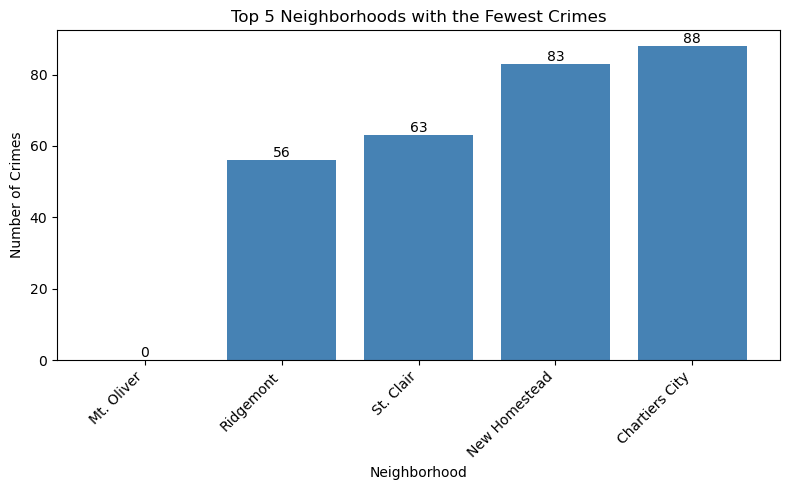

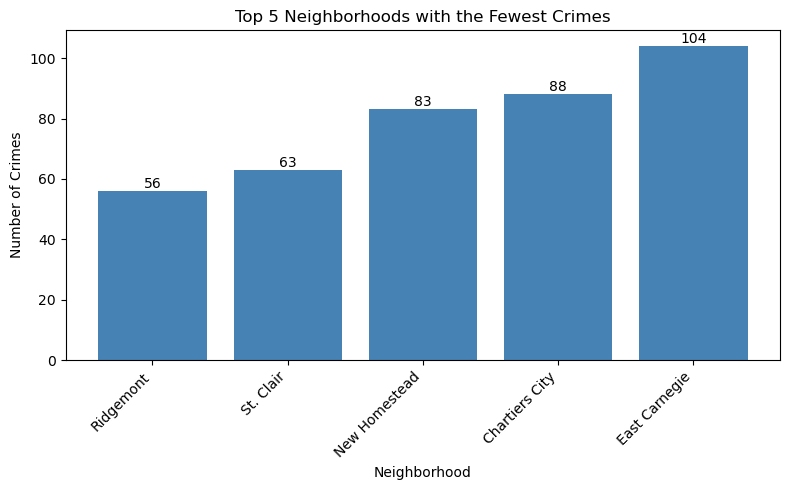

In [13]:
plt.figure(figsize=(8, 5))
plt.bar(top5["Neighborhood"], top5["Crime Count"], color="steelblue")

for i, v in enumerate(top5["Crime Count"]):
    plt.text(i, v, str(v), ha="center", va="bottom")

plt.title("Top 5 Neighborhoods with the Fewest Crimes")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Crimes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### The Best Neighborhood

My submetric focuses on identifying Pittsburgh neighborhoods with the lowest crime rates to help determine which areas may offer a safer and better socio-economic environments. By looking at the number of reported crimes in each neighborhood, I can compare crime levels and identify the areas with fewer reported incidents.

What I find interesting is that a lower number of reported crimes does not automatically mean a neighborhood is safer. Neighborhood population, size, and the number of people visiting an area can all affect crime totals. For example, a neighborhood with fewer residents may naturally have fewer reported incidents than a much more populated neighborhood. This is why looking at crime rates rather than just total crime counts can provide a more accurate comparison.

One limitation of my submetric is that it only measures reported crime and does not consider every aspect of a neighborhood's socio-economic environment. Factors such as affordability, employment opportunities, education, transportation, and access to resources also contribute to quality of life. My submetric provides one perspective on neighborhood conditions, which is why it should be combined with the other submetrics to determine the best overall Pittsburgh neighborhoods.



### Conclusion



### The Best Neighborhood
Apply the metric from the previous section to determine the best neighborhood in Pittsburgh. Beyond just executing code, provide a narrative about why you think this is the best neighborhood. Incorporate a data visualization, perhaps to rank all of the neighborhoods or show a neighborhood’s best-ness over time. The key is to make a data driven argument.

### Conclusion
Reflect on how the data-driven determination of “best neighborhood” is the same or different from your personal favorite neighborhood. Each member of the group should write their own response to this.